# M5 Exploratory Data Analysis — Walmart Retail Demand

**Project:** Agentic AI for Retail Demand & Inventory Decision Support (IDS 560, Group 4)
**Data:** M5 Forecasting (Walmart-originated, Kaggle): `calendar`, `sell_prices`, `sales_train_evaluation`

**How the notebook is organized.** Each section follows the same pattern: *question → method → output → findings*.

| # | Section | Question it answers |
|---|---|---|
| 1 | Load and overview | What do we have, and how big is it? |
| 2 | Data quality | What is missing, inconsistent, or unusual? |
| 3 | Structure and concentration | Where does the volume sit? |
| 4 | Trends and seasonality | How does demand move over time? |
| 5 | Calendar effects | Do events, weekdays, and SNAP days matter? |
| 6 | Prices | How do prices behave, and how do sales react to them? |
| 7 | Demand patterns | How intermittent is demand? Which models does that favor? |
| 8 | Scope sizing | What manageable subset covers most of the value? |
| 9 | Findings and implications | What does it all mean for modeling? |

Run the cells top to bottom. **Findings cells are blank on purpose**: fill them from the numbers that print.
Charts are saved as PNGs to a `charts/` folder next to `datasets/`.

## 1. Load and overview

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN slices are expected here

SALES_FILE = "sales_train_evaluation.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)          # each person signs in with their own Google account
except ImportError:
    pass

# --- Locate the shared data folder automatically (works for Shared drives and for My Drive shortcuts) ---
# Leave BASE_PATH as None to auto-detect. Only set it by hand if auto-detect finds the wrong folder, e.g.
# BASE_PATH = "/content/drive/Shareddrives/<drive name>/<folders>/M5 EDA/datasets/"
BASE_PATH = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/datasets/"

def find_datasets_folders():
    import glob
    found = []
    for root in ["/content/drive/Shareddrives/*", "/content/drive/MyDrive"]:
        for depth in range(0, 4):                       # looks up to 3 folders deep
            pattern = os.path.join(root, *(["*"] * depth), "M5 EDA", "datasets")
            found += [p for p in glob.glob(pattern) if os.path.isdir(p)]
    return found

if BASE_PATH is None:
    matches = find_datasets_folders()
    if not matches:
        raise FileNotFoundError(
            "Could not find 'M5 EDA/datasets' in your Shared drives or My Drive. "
            "One-time fix: in Google Drive open 'Shared with me', right-click the folder "
            "'IDS 560- Agentic AI & Inventory Project', choose Organize > Add shortcut > My Drive, then re-run this cell. "
            "(Or set BASE_PATH by hand above.)")
    BASE_PATH = matches[0].rstrip("/") + "/"
    print("Using data folder:", BASE_PATH)
    if len(matches) > 1:
        print("Other matching folders were ignored:", matches[1:])

missing = [f for f in ["calendar.csv", "sell_prices.csv", SALES_FILE] if not os.path.exists(BASE_PATH + f)]
if missing:
    raise FileNotFoundError(f"Missing in {BASE_PATH}: {missing}. Files found: {sorted(os.listdir(BASE_PATH))[:20]}")

NAVY, ACCENT, LIGHT, GRAY = "#142F52", "#3E75BC", "#8FB4E3", "#5D6B7B"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10,
})
CHART_DIR = os.path.join(os.path.dirname(BASE_PATH.rstrip("/")), "charts") + "/"
try:
    os.makedirs(CHART_DIR, exist_ok=True)
except OSError:                                       # e.g. view-only access to the shared folder
    CHART_DIR = "/content/charts/"
    os.makedirs(CHART_DIR, exist_ok=True)
    print("No write access to the shared folder. Charts will be saved to", CHART_DIR, "(download them from the Colab file panel).")
print("Charts will be saved to:", CHART_DIR)

def save_chart(name=None):
    plt.tight_layout()
    plt.show()

Mounted at /content/drive
Charts will be saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/charts/


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Memory-efficient loading: small integer types for sales/weeks, float32 for prices, categories for IDs.
calendar = pd.read_csv(BASE_PATH + "calendar.csv", parse_dates=["date"])

prices = pd.read_csv(BASE_PATH + "sell_prices.csv",
                     dtype={"store_id": "category", "item_id": "category",
                            "wm_yr_wk": "int16", "sell_price": "float32"})

ID_COLS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
_header = pd.read_csv(BASE_PATH + SALES_FILE, nrows=1).columns
day_cols = [c for c in _header if c.startswith("d_")]
sales = pd.read_csv(BASE_PATH + SALES_FILE,
                    dtype={**{c: "category" for c in ID_COLS[1:]}, **{c: "int16" for c in day_cols}})

print("calendar:", calendar.shape, "| prices:", prices.shape, "| sales:", sales.shape)

calendar: (1969, 14) | prices: (6841121, 4) | sales: (30490, 1947)


In [5]:
# Working objects used throughout the notebook
vals = sales[day_cols].to_numpy(dtype=np.int32)                 # series x days
n_series, n_days = vals.shape

cal_by_d = calendar.set_index("d")
dates = pd.DatetimeIndex(cal_by_d.loc[day_cols, "date"])        # one date per sales column
week_of_day = cal_by_d.loc[day_cols, "wm_yr_wk"].to_numpy()

series = sales[ID_COLS].copy()
for c in ID_COLS[1:]:
    series[c] = series[c].astype(str)

daily_total = pd.Series(vals.sum(axis=0, dtype=np.int64), index=dates)
print(f"{n_series:,} Item x Store series x {n_days:,} days = {vals.size:,} observations")

30,490 Item x Store series x 1,941 days = 59,181,090 observations


In [6]:
overview = pd.DataFrame([
    ["calendar",    len(calendar),  calendar.shape[1], "Day",                                  "d (date, wm_yr_wk)",             calendar.memory_usage(deep=True).sum() / 1e6],
    ["sell_prices", len(prices),    prices.shape[1],   "Item x Store x Week",                  "item_id + store_id + wm_yr_wk",  prices.memory_usage(deep=True).sum() / 1e6],
    ["sales",       len(sales),     sales.shape[1],    "Item x Store (wide: one column/day)",  "item_id + store_id",             sales.memory_usage(deep=True).sum() / 1e6],
], columns=["file", "rows", "columns", "grain", "key", "memory_MB"])
overview["rows"] = overview["rows"].map("{:,}".format)
overview["memory_MB"] = overview["memory_MB"].round(0)
overview

,file,rows,columns,grain,key,memory_MB
0,calendar,"1,969",14,Day,"d (date, wm_yr_wk)",1.0
1,sell_prices,"6,841,121",4,Item x Store x Week,item_id + store_id + wm_yr_wk,62.0
2,sales,"30,490",1947,Item x Store (wide: one column/day),item_id + store_id,121.0


In [7]:
print("Sales window     :", dates[0].date(), "to", dates[-1].date(), f"({n_days:,} days)")
print("Calendar window  :", calendar["date"].min().date(), "to", calendar["date"].max().date(), f"({len(calendar):,} days)")
print("Days with no sales (forecast window):", len(calendar) - n_days)
print()
print("Hierarchy:", series["state_id"].nunique(), "states |", series["store_id"].nunique(), "stores |",
      series["cat_id"].nunique(), "categories |", series["dept_id"].nunique(), "departments |",
      series["item_id"].nunique(), "items")

Sales window     : 2011-01-29 to 2016-05-22 (1,941 days)
Calendar window  : 2011-01-29 to 2016-06-19 (1,969 days)
Days with no sales (forecast window): 28

Hierarchy: 3 states | 10 stores | 3 categories | 7 departments | 3049 items


## 2. Data quality

### 2.1 Missing values

In [8]:
def missing_table(df, name):
    m = df.isna().sum()
    m = m[m > 0]
    return pd.DataFrame({"file": name, "column": m.index, "missing": m.values,
                         "missing_%": (m.values / len(df) * 100).round(1)})

miss = pd.concat([missing_table(calendar, "calendar"), missing_table(prices, "sell_prices"),
                  missing_table(sales, "sales")], ignore_index=True)
print("Total missing cells in prices:", int(prices.isna().sum().sum()), "| in sales:", int(sales.isna().sum().sum()))
miss

Total missing cells in prices: 0 | in sales: 0


,file,column,missing,missing_%
0,calendar,event_name_1,1807,91.8
1,calendar,event_type_1,1807,91.8
2,calendar,event_name_2,1964,99.7
3,calendar,event_type_2,1964,99.7


The only literal missing values are in the calendar's event columns, and they mean *no event that day*.
The sales and price files have no missing cells. **The real gaps are structural** (rows that do not exist, zeros that are not demand), covered next.

### 2.2 Structural gaps: zeros and missing price weeks

In [9]:
# Align prices to the sales grid: one price per series per week (NaN = no price row that week)
starts = np.r_[0, np.flatnonzero(np.diff(week_of_day)) + 1]
weeks_in_sales = week_of_day[starts]
weekly_units = np.add.reduceat(vals, starts, axis=1, dtype=np.int64)        # series x weeks
n_weeks = len(starts)

item_list, store_list = sorted(series["item_id"].unique()), sorted(series["store_id"].unique())
lookup = np.full(len(item_list) * len(store_list), -1, dtype=np.int64)
s_item  = pd.Categorical(series["item_id"],  categories=item_list).codes.astype(np.int64)
s_store = pd.Categorical(series["store_id"], categories=store_list).codes.astype(np.int64)
lookup[s_item * len(store_list) + s_store] = np.arange(n_series)

p_item  = pd.Categorical(prices["item_id"],  categories=item_list).codes.astype(np.int64)
p_store = pd.Categorical(prices["store_id"], categories=store_list).codes.astype(np.int64)
ok = (p_item >= 0) & (p_store >= 0)
row_idx = np.full(len(prices), -1, dtype=np.int64)
row_idx[ok] = lookup[p_item[ok] * len(store_list) + p_store[ok]]

wk = prices["wm_yr_wk"].to_numpy().astype(np.int64)
wk_min = int(week_of_day.min())
wk_lookup = np.full(int(max(wk.max(), week_of_day.max())) - wk_min + 1, -1, dtype=np.int64)
wk_lookup[weeks_in_sales.astype(np.int64) - wk_min] = np.arange(n_weeks)
col_idx = np.full(len(prices), -1, dtype=np.int64)
inr = wk >= wk_min
col_idx[inr] = wk_lookup[wk[inr] - wk_min]

keep = (row_idx >= 0) & (col_idx >= 0)
P = np.full((n_series, n_weeks), np.nan, dtype=np.float32)
P[row_idx[keep], col_idx[keep]] = prices["sell_price"].to_numpy()[keep]
print("Price matrix:", P.shape, "(series x weeks in the sales window)")

Price matrix: (30490, 278) (series x weeks in the sales window)


In [10]:
zero_mask = (vals == 0)
has_sale = ~zero_mask
first_sale = np.where(has_sale.any(axis=1), has_sale.argmax(axis=1), n_days)
after_first = np.arange(n_days)[None, :] >= first_sale[:, None]

no_price = np.isnan(P)
full_grid = n_series * len(np.unique(prices["wm_yr_wk"]))
units_no_price = weekly_units[no_price]

gaps = pd.DataFrame([
    ["Zero-sales observations (all)",                         f"{zero_mask.mean():.1%}"],
    ["  of which: leading zeros (before first sale)",         f"{first_sale.sum() / vals.size:.1%}"],
    ["Zeros after the first sale, as % of days after launch", f"{(zero_mask & after_first).sum() / max(after_first.sum(), 1):.1%}"],
    ["Series that never sell",                                 f"{int((~has_sale.any(axis=1)).sum()):,}"],
    ["Price rows vs. a full Item x Store x Week grid",        f"{len(prices) / full_grid:.1%}"],
    ["Price coverage inside the sales window",                f"{(~no_price).mean():.1%}"],
    ["Weeks with no price: share that still had sales",       f"{(units_no_price > 0).mean():.2%}" if units_no_price.size else "n/a"],
], columns=["check", "result"])
gaps

,check,result
0,Zero-sales observations (all),68.0%
1,of which: leading zeros (before first sale),20.9%
2,"Zeros after the first sale, as % of days after...",59.5%
3,Series that never sell,0
4,Price rows vs. a full Item x Store x Week grid,79.6%
5,Price coverage inside the sales window,79.3%
6,Weeks with no price: share that still had sales,0.00%


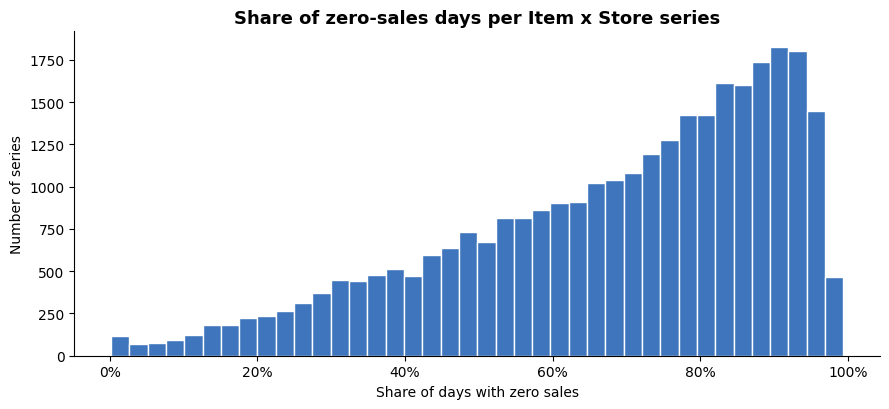

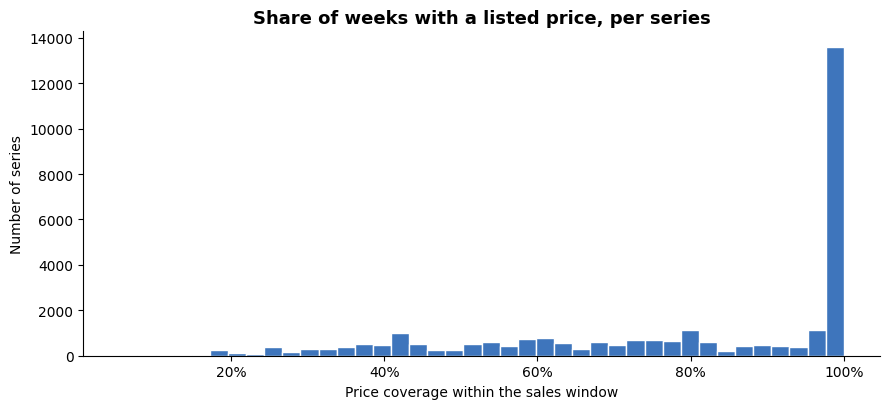

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(zero_mask.mean(axis=1), bins=40, color=ACCENT, edgecolor="white")
ax.set_title("Share of zero-sales days per Item x Store series")
ax.set_xlabel("Share of days with zero sales"); ax.set_ylabel("Number of series")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
save_chart("quality_zero_share_hist")

cov = (~no_price).mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(cov, bins=40, color=ACCENT, edgecolor="white")
ax.set_title("Share of weeks with a listed price, per series")
ax.set_xlabel("Price coverage within the sales window"); ax.set_ylabel("Number of series")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
save_chart("quality_price_coverage_hist")

**Reading this.** If weeks without a price almost never have sales, a missing price means *the item was not on sale*, so those zeros are not real demand zeros.
Leading zeros (before an item's first sale) are the same story. They should be trimmed before training or modeling.

### 2.3 Integrity checks

In [12]:
pairs_with_price = np.unique(row_idx[row_idx >= 0]).size
checks = [
    ("calendar: `d` is unique",                                   calendar["d"].is_unique),
    ("calendar: `date` is unique",                                calendar["date"].is_unique),
    ("sales: every day column exists in the calendar",            set(day_cols) <= set(calendar["d"])),
    ("sales: Item x Store is unique",                             not series.duplicated(["item_id", "store_id"]).any()),
    ("prices: every price week exists in the calendar",           set(prices["wm_yr_wk"].unique()) <= set(calendar["wm_yr_wk"])),
    ("prices: Item x Store x Week is unique",                     not prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).any()),
    ("sales -> prices: every sales series has price rows",        pairs_with_price == n_series),
    ("sales: no negative units",                                  bool(vals.min() >= 0)),
    ("prices: all prices are positive",                           bool((prices["sell_price"] > 0).all())),
]
integrity = pd.DataFrame(checks, columns=["check", "passed"])
integrity["status"] = np.where(integrity["passed"], "PASS", "FAIL")
integrity[["check", "status"]]

,check,status
0,calendar: `d` is unique,PASS
1,calendar: `date` is unique,PASS
2,sales: every day column exists in the calendar,PASS
3,sales: Item x Store is unique,PASS
4,prices: every price week exists in the calendar,PASS
5,prices: Item x Store x Week is unique,PASS
6,sales -> prices: every sales series has price ...,PASS
7,sales: no negative units,PASS
8,prices: all prices are positive,PASS


### 2.4 Outliers

In [13]:
flat = vals.ravel()
top = np.argpartition(flat, -10)[-10:]
top = top[np.argsort(flat[top])[::-1]]
r, c = np.divmod(top, n_days)
top_cells = pd.DataFrame({
    "item_id": series["item_id"].to_numpy()[r], "store_id": series["store_id"].to_numpy()[r],
    "date": dates[c].date, "units": vals[r, c],
    "typical_day_when_selling": [int(np.median(vals[i][vals[i] > 0])) for i in r],
})
top_cells

,item_id,store_id,date,units,typical_day_when_selling
0,FOODS_3_090,CA_3,2013-09-14,763,146
1,FOODS_3_090,CA_3,2013-09-13,709,146
2,FOODS_3_090,CA_3,2013-08-23,709,146
3,FOODS_3_090,CA_3,2011-12-31,693,146
4,FOODS_3_785,CA_1,2012-06-22,648,12
5,FOODS_2_285,TX_1,2011-05-06,634,4
6,FOODS_3_090,CA_3,2011-12-23,633,146
7,HOUSEHOLD_1_474,TX_2,2013-07-24,626,7
8,FOODS_3_090,CA_3,2013-09-11,620,146
9,FOODS_3_090,CA_3,2011-12-24,619,146


In [14]:
p99 = np.percentile(vals, 99, axis=1)
spike = vals > np.maximum(5 * p99[:, None], 20)
print(f"Spike days (> 5x the series' own 99th percentile and >= 20 units): {spike.sum():,} "
      f"({spike.mean():.3%} of observations) across {int(spike.any(axis=1).sum()):,} series")

chg = P[:, 1:] / P[:, :-1] - 1
print(f"Week-over-week price moves larger than +/-50%: {int((np.abs(chg) > 0.5).sum()):,} "
      f"({np.nanmean(np.abs(chg) > 0.5):.3%} of observed pairs)")

Spike days (> 5x the series' own 99th percentile and >= 20 units): 323 (0.001% of observations) across 270 series
Week-over-week price moves larger than +/-50%: 6,595 (0.078% of observed pairs)


## 3. Structure and concentration

In [15]:
series["units"] = vals.sum(axis=1, dtype=np.int64)
series["revenue"] = (weekly_units * np.nan_to_num(P, nan=0.0)).sum(axis=1)     # estimated: weekly units x weekly price
series["zero_share"] = zero_mask.mean(axis=1)

def share_table(col):
    t = series.groupby(col).agg(series=("id", "count"), units=("units", "sum"), revenue=("revenue", "sum"))
    t["% of units"] = (t["units"] / t["units"].sum() * 100).round(1)
    t["% of revenue"] = (t["revenue"] / t["revenue"].sum() * 100).round(1)
    return t[["series", "% of units", "% of revenue"]]

print("By category"); display(share_table("cat_id"))
print("By state");    display(share_table("state_id"))
print("By department"); display(share_table("dept_id"))

By category


,series,% of units,% of revenue
cat_id,,,
FOODS,14370,68.6,58.0
HOBBIES,5650,9.3,12.2
HOUSEHOLD,10470,22.1,29.8


By state


,series,% of units,% of revenue
state_id,,,
CA,12196,43.6,44.9
TX,9147,28.7,28.8
WI,9147,27.6,26.4


By department


,series,% of units,% of revenue
dept_id,,,
FOODS_1,2160,7.8,6.9
FOODS_2,3980,11.6,13.4
FOODS_3,8230,49.2,37.8
HOBBIES_1,4160,8.5,11.5
HOBBIES_2,1490,0.8,0.6
HOUSEHOLD_1,5320,17.5,22.0
HOUSEHOLD_2,5150,4.5,7.8


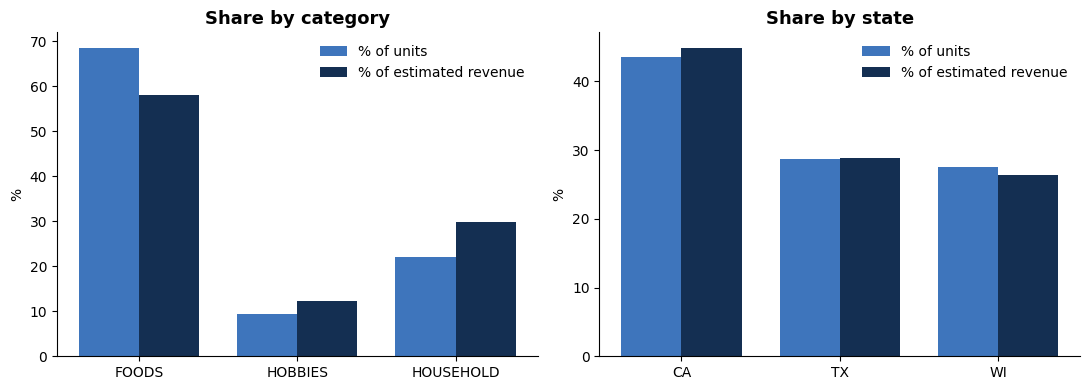

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["cat_id", "state_id"], ["Share by category", "Share by state"]):
    t = share_table(col)
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w / 2, t["% of units"], w, color=ACCENT, label="% of units")
    ax.bar(x + w / 2, t["% of revenue"], w, color=NAVY, label="% of estimated revenue")
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_title(title); ax.set_ylabel("%")
    ax.legend(frameon=False)
save_chart("structure_share_category_state")

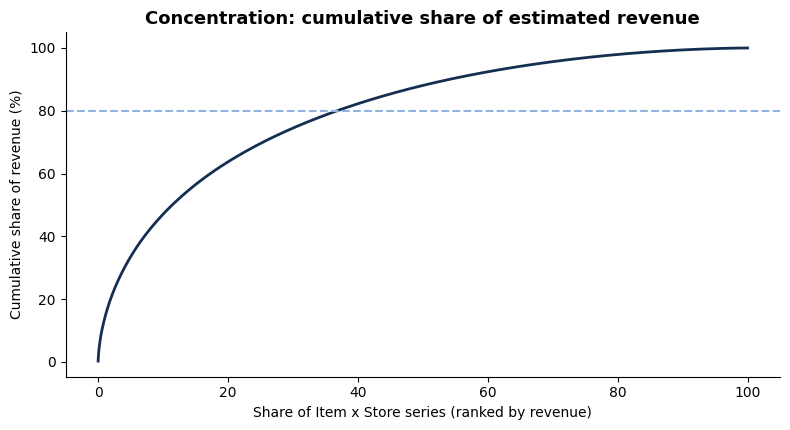

Series needed to reach 50% / 80% / 90% of revenue: 3483 / 11222 / 16491


,top % of series,share of revenue (%),series
0,1,13.7,304
1,5,33.4,1524
2,10,47.0,3049
3,20,63.7,6098
4,50,88.1,15245


In [17]:
order = series.sort_values("revenue", ascending=False)
cum = order["revenue"].cumsum().to_numpy() / order["revenue"].sum()
x = np.arange(1, n_series + 1) / n_series

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(x * 100, cum * 100, color=NAVY, linewidth=2)
ax.set_title("Concentration: cumulative share of estimated revenue")
ax.set_xlabel("Share of Item x Store series (ranked by revenue)"); ax.set_ylabel("Cumulative share of revenue (%)")
ax.axhline(80, color=LIGHT, linestyle="--");
save_chart("structure_pareto_revenue")

conc = pd.DataFrame({
    "top % of series": [1, 5, 10, 20, 50],
    "share of revenue (%)": [round(cum[int(n_series * p / 100) - 1] * 100, 1) for p in [1, 5, 10, 20, 50]],
})
conc["series"] = (n_series * conc["top % of series"] / 100).astype(int)
print("Series needed to reach 50% / 80% / 90% of revenue:",
      int(np.searchsorted(cum, 0.5)) + 1, "/", int(np.searchsorted(cum, 0.8)) + 1, "/", int(np.searchsorted(cum, 0.9)) + 1)
conc

In [18]:
top_items = (series.groupby("item_id")["revenue"].sum().sort_values(ascending=False).head(10) / series["revenue"].sum() * 100).round(2)
top_items.rename("% of total revenue").to_frame()

,% of total revenue
item_id,
FOODS_3_586,0.77
FOODS_3_120,0.75
FOODS_3_090,0.72
FOODS_3_202,0.66
FOODS_3_587,0.52
FOODS_3_252,0.46
FOODS_3_555,0.41
FOODS_3_444,0.38
HOBBIES_1_354,0.37


## 4. Trends and seasonality

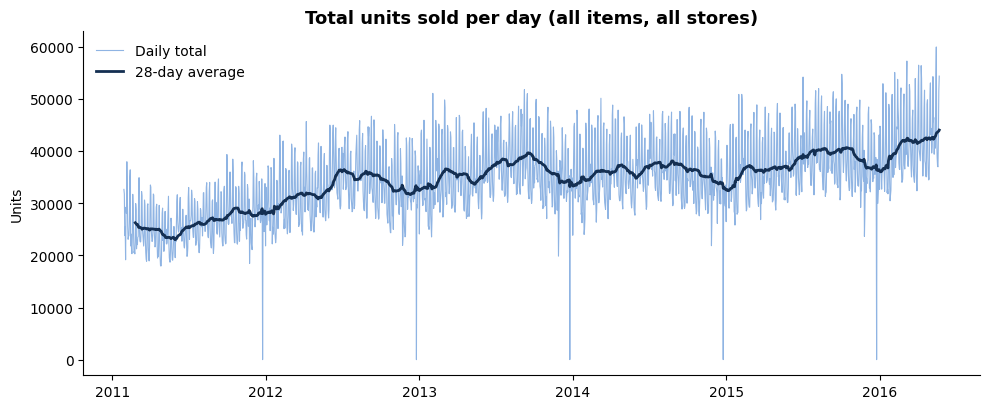

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(daily_total.index, daily_total.values, color=LIGHT, linewidth=0.8, label="Daily total")
ax.plot(daily_total.index, daily_total.rolling(28).mean(), color=NAVY, linewidth=2, label="28-day average")
ax.set_title("Total units sold per day (all items, all stores)"); ax.set_ylabel("Units")
ax.legend(frameon=False)
save_chart("trend_total_daily")

In [20]:
year_tab = daily_total.groupby(dates.year).agg(units="sum", days="count")
year_tab["avg_daily_units"] = (year_tab["units"] / year_tab["days"]).round(0)
year_tab["complete_year"] = year_tab["days"] >= 365
year_tab["growth_vs_prev_year_%"] = (year_tab["avg_daily_units"].pct_change() * 100).round(1)
display(year_tab)

last = dates[-1]
ytd_now  = daily_total[(dates.year == last.year)].sum()
ytd_prev = daily_total[(dates.year == last.year - 1) & (dates.dayofyear <= last.dayofyear)].sum()
print(f"Like-for-like growth, Jan 1 to {last.strftime('%b %d')}: {last.year} vs {last.year - 1} = {ytd_now / ytd_prev - 1:+.1%}")

,units,days,avg_daily_units,complete_year,growth_vs_prev_year_%
date,,,,,
2011,8856585,337,26281.0,False,NaN
2012,12061837,366,32956.0,True,25.4
2013,13135753,365,35988.0,True,9.2
2014,13089776,365,35862.0,True,-0.4
2015,13800811,365,37810.0,True,5.4
2016,5982411,143,41835.0,False,10.6


Like-for-like growth, Jan 1 to May 22: 2016 vs 2015 = +15.1%


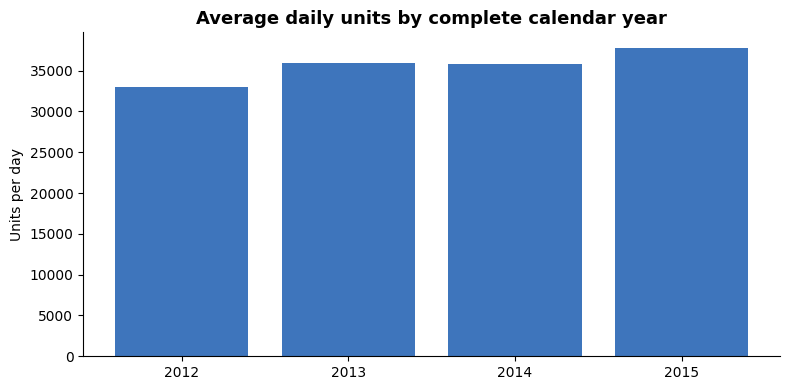

In [21]:
full = year_tab[year_tab["complete_year"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(full.index.astype(str), full["avg_daily_units"], color=ACCENT)
ax.set_title("Average daily units by complete calendar year"); ax.set_ylabel("Units per day")
save_chart("trend_annual_avg_daily")

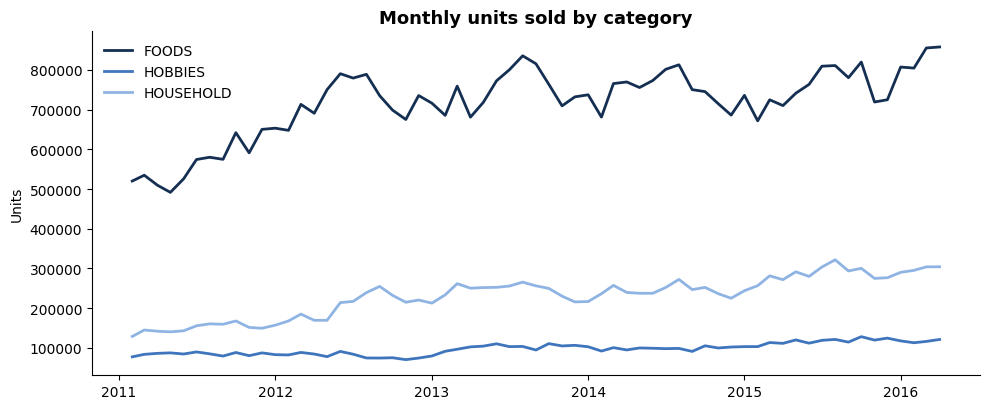

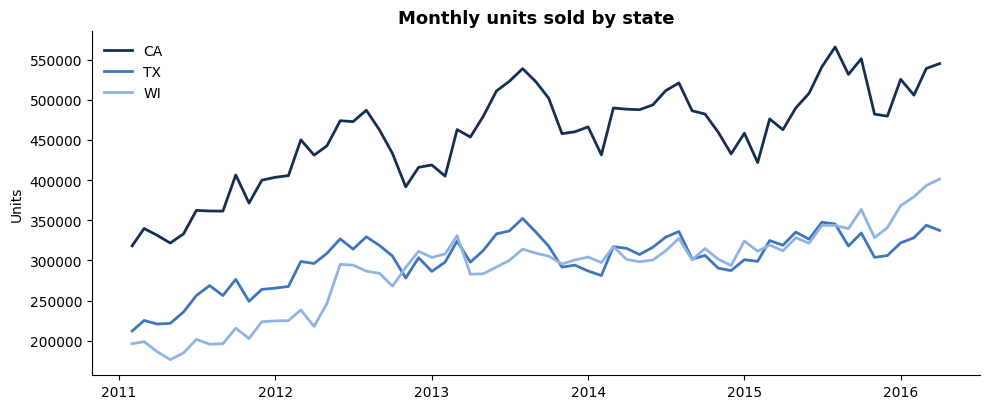

In [22]:
# Monthly trend by category and by state (first and last months are partial, so they are dropped)
def monthly_lines(group_col, filename, title):
    g = pd.DataFrame({k: vals[(series[group_col] == k).to_numpy()].sum(axis=0, dtype=np.int64)
                      for k in sorted(series[group_col].unique())}, index=dates)
    m = g.resample("MS").sum().iloc[1:-1]
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for col, color in zip(m.columns, [NAVY, ACCENT, LIGHT]):
        ax.plot(m.index, m[col], label=col, color=color, linewidth=2)
    ax.set_title(title); ax.set_ylabel("Units"); ax.legend(frameon=False)
    save_chart(filename)

monthly_lines("cat_id", "trend_monthly_by_category", "Monthly units sold by category")
monthly_lines("state_id", "trend_monthly_by_state", "Monthly units sold by state")

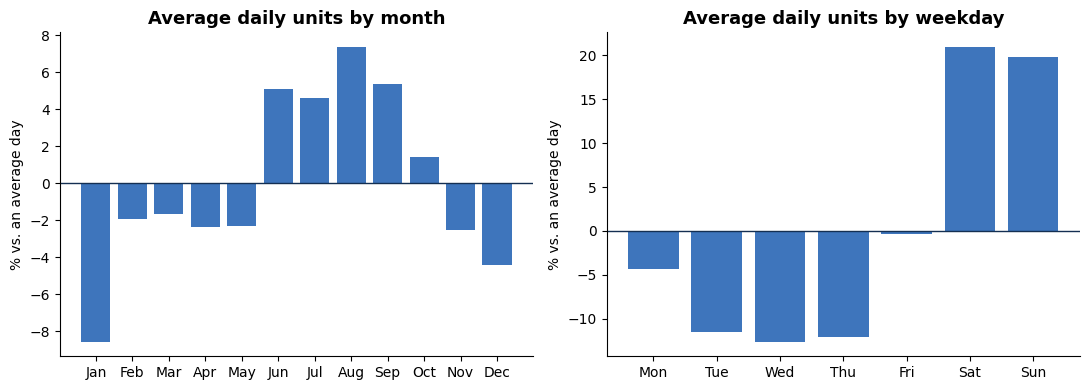

Strongest month: 8 (1.07)  | weakest: 1 (0.91)
Strongest weekday: Sat (1.21)  | weakest: Wed (0.87)


In [23]:
# Seasonality uses complete years only
yr = (dates.year >= year_tab.index[year_tab["complete_year"]].min()) & (dates.year <= year_tab.index[year_tab["complete_year"]].max())
sub = daily_total[yr]

month_idx = sub.groupby(sub.index.month).mean() / sub.mean()
dow_idx   = daily_total.groupby(dates.dayofweek).mean() / daily_total.mean()
dow_idx.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], (month_idx.values - 1) * 100, color=ACCENT)
axes[0].axhline(0, color=NAVY, linewidth=1); axes[0].set_title("Average daily units by month"); axes[0].set_ylabel("% vs. an average day")
axes[1].bar(dow_idx.index, (dow_idx.values - 1) * 100, color=ACCENT)
axes[1].axhline(0, color=NAVY, linewidth=1); axes[1].set_title("Average daily units by weekday"); axes[1].set_ylabel("% vs. an average day")
save_chart("seasonality_month_weekday")
print("Strongest month:", month_idx.idxmax(), f"({month_idx.max():.2f})  | weakest:", month_idx.idxmin(), f"({month_idx.min():.2f})")
print("Strongest weekday:", dow_idx.idxmax(), f"({dow_idx.max():.2f})  | weakest:", dow_idx.idxmin(), f"({dow_idx.min():.2f})")

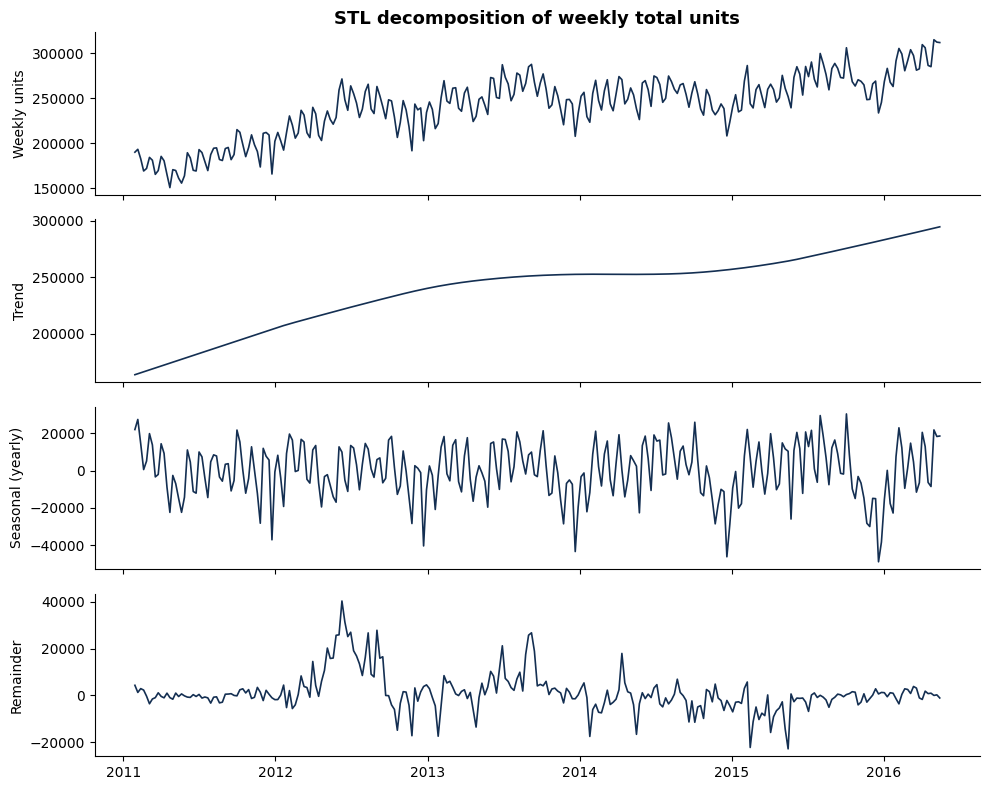

In [24]:
# Trend / seasonal / remainder split of weekly totals (STL)
try:
    from statsmodels.tsa.seasonal import STL
    wk_total = pd.Series(weekly_units.sum(axis=0), index=dates[starts])
    if n_days - starts[-1] < 7:          # the last week is partial, so drop it
        wk_total = wk_total.iloc[:-1]
    res = STL(wk_total, period=52, robust=True).fit()
    fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    for ax, s, t in zip(axes, [wk_total, res.trend, res.seasonal, res.resid], ["Weekly units", "Trend", "Seasonal (yearly)", "Remainder"]):
        ax.plot(s.index, s.values, color=NAVY, linewidth=1.2); ax.set_ylabel(t)
    axes[0].set_title("STL decomposition of weekly total units")
    save_chart("trend_stl_weekly")
except Exception as e:
    print("STL skipped:", e)

## 5. Calendar effects: events, SNAP days, unusual days

In [25]:
# Remove the weekday pattern, then compare each day with its local baseline.
adj = daily_total / dow_idx.set_axis(range(7)).reindex(dates.dayofweek).to_numpy()
baseline = adj.rolling(29, center=True, min_periods=15).median()
lift = (adj / baseline - 1)

ev = pd.DataFrame({"event": cal_by_d.loc[day_cols, "event_name_1"].to_numpy(), "type": cal_by_d.loc[day_cols, "event_type_1"].to_numpy(),
                   "lift": lift.to_numpy()}).dropna(subset=["event"])
ev_sum = ev.groupby("event").agg(days=("lift", "count"), avg_lift=("lift", "mean"), type=("type", "first"))
ev_sum = ev_sum[ev_sum["days"] >= 3].sort_values("avg_lift")
ev_sum["avg_lift_%"] = (ev_sum["avg_lift"] * 100).round(1)
print("Events with at least 3 occurrences:", len(ev_sum))
shown = ev_sum if len(ev_sum) <= 10 else pd.concat([ev_sum.head(5), ev_sum.tail(5)])
display(shown[["type", "days", "avg_lift_%"]])

Events with at least 3 occurrences: 30


,type,days,avg_lift_%
event,,,
Christmas,National,5,-100.0
Thanksgiving,National,5,-28.7
NewYear,National,5,-21.4
Mother's day,Cultural,6,-13.1
Easter,Cultural,5,-10.6
Cinco De Mayo,Cultural,5,3.9
MemorialDay,National,5,3.9
PresidentsDay,National,6,4.2
VeteransDay,National,5,5.0


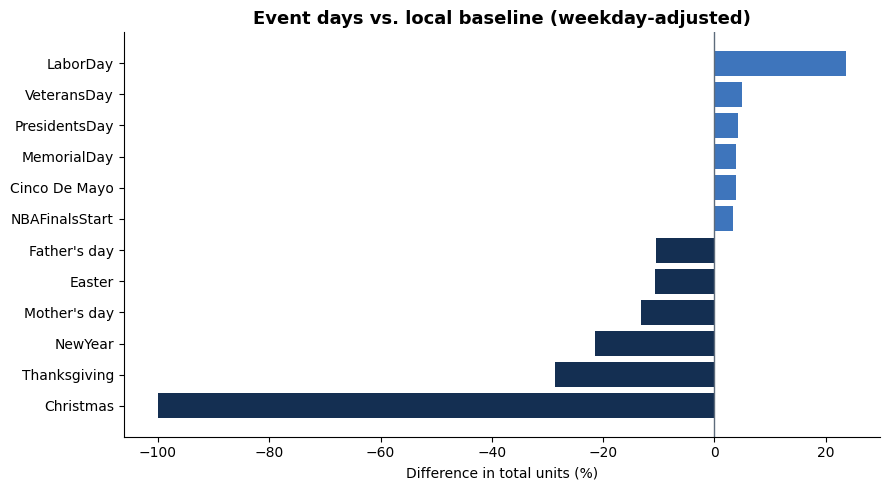

In [26]:
show = ev_sum if len(ev_sum) <= 12 else pd.concat([ev_sum.head(6), ev_sum.tail(6)])
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(show.index, show["avg_lift_%"], color=[NAVY if v < 0 else ACCENT for v in show["avg_lift_%"]])
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_title("Event days vs. local baseline (weekday-adjusted)")
ax.set_xlabel("Difference in total units (%)")
save_chart("calendar_event_lift")

In [27]:
lowest = daily_total.nsmallest(8).to_frame("units")
lowest["event"] = cal_by_d.loc[[day_cols[dates.get_loc(d)] for d in lowest.index], "event_name_1"].to_numpy()
lowest

,units,event
date,,
2012-12-25,11,Christmas
2011-12-25,13,Christmas
2015-12-25,14,Christmas
2013-12-25,20,Christmas
2014-12-25,20,Christmas
2011-04-27,17929,NaN
2011-04-26,18113,Pesach End
2011-04-28,18145,NaN


In [28]:
# SNAP days: weekday-adjusted average on SNAP days vs. other days, by state and category
rows = []
for st in sorted(series["state_id"].unique()):
    flag = (cal_by_d.loc[day_cols, f"snap_{st}"].to_numpy() == 1)
    for cat in sorted(series["cat_id"].unique()):
        m = ((series["state_id"] == st) & (series["cat_id"] == cat)).to_numpy()
        d = pd.Series(vals[m].sum(axis=0, dtype=np.int64), index=dates)
        a = d / (d.groupby(dates.dayofweek).mean() / d.mean()).reindex(dates.dayofweek).to_numpy()
        rows.append([st, cat, a[flag].mean() / a[~flag].mean() - 1])
snap = pd.DataFrame(rows, columns=["state", "category", "snap_vs_other_days"]).pivot(index="state", columns="category", values="snap_vs_other_days")
(snap * 100).round(1)

category,FOODS,HOBBIES,HOUSEHOLD
state,,,
CA,10.6,3.2,3.9
TX,15.9,2.2,3.3
WI,30.4,1.9,3.9


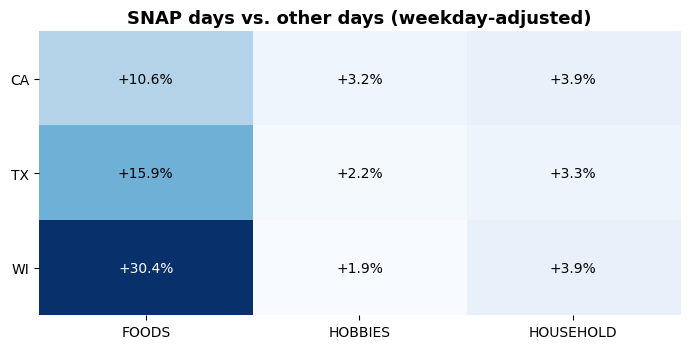

In [29]:
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(snap.values * 100, cmap="Blues", aspect="auto")
ax.set_xticks(range(snap.shape[1])); ax.set_xticklabels(snap.columns)
ax.set_yticks(range(snap.shape[0])); ax.set_yticklabels(snap.index)
for i in range(snap.shape[0]):
    for j in range(snap.shape[1]):
        dark = snap.values[i, j] > 0.6 * np.nanmax(snap.values)
        ax.text(j, i, f"{snap.values[i, j] * 100:+.1f}%", ha="center", va="center", color="white" if dark else "black", fontsize=10)
ax.set_title("SNAP days vs. other days (weekday-adjusted)")
ax.spines[:].set_visible(False)
save_chart("calendar_snap_effect")

## 6. Prices

In [30]:
item_prefix = np.array(pd.Index(prices["item_id"].cat.categories).str.split("_").str[0])
cat_names, per_item_cat = np.unique(item_prefix, return_inverse=True)
price_cat_code = per_item_cat[prices["item_id"].cat.codes.to_numpy()]

rows = []
for k, name in enumerate(cat_names):
    s = prices.loc[price_cat_code == k, "sell_price"]
    rows.append([name, len(s), s.mean(), s.median(), s.quantile(0.05), s.quantile(0.95), s.max()])
pd.DataFrame(rows, columns=["category", "rows", "mean", "median", "p5", "p95", "max"]).round(2)

,category,rows,mean,median,p5,p95,max
0,FOODS,3181789,3.25,2.68,1.00,7.27,19.48
1,HOBBIES,1283905,5.33,3.97,0.50,14.66,30.98
2,HOUSEHOLD,2375427,5.47,4.94,1.24,11.86,107.32


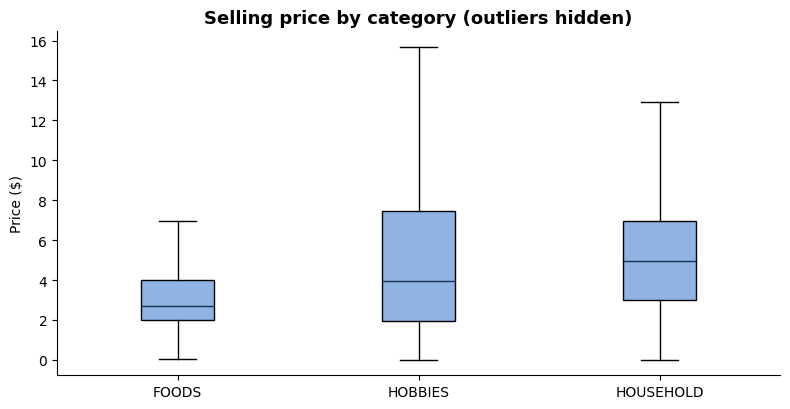

In [31]:
data = []
for k in range(len(cat_names)):
    s = prices.loc[price_cat_code == k, "sell_price"]
    data.append(s.sample(min(len(s), 200_000), random_state=1).to_numpy())

fig, ax = plt.subplots(figsize=(8, 4.2))
bp = ax.boxplot(data, showfliers=False, patch_artist=True)
for patch in bp["boxes"]: patch.set_facecolor(LIGHT)
for med in bp["medians"]: med.set_color(NAVY)
ax.set_xticks(range(1, len(cat_names) + 1)); ax.set_xticklabels(cat_names)
ax.set_title("Selling price by category (outliers hidden)"); ax.set_ylabel("Price ($)")
save_chart("prices_by_category")

In [32]:
n_changes = (np.abs(np.diff(P, axis=1)) > 1e-6).sum(axis=1)
varying = n_changes > 0
print(f"Series whose price changes at least once: {varying.mean():.1%}")
print(f"Typical number of price changes per series: median {int(np.median(n_changes))}, 90th percentile {int(np.percentile(n_changes, 90))}")

Series whose price changes at least once: 72.8%
Typical number of price changes per series: median 2, 90th percentile 6


In [33]:
# Do sales move when the price moves? Compare each series' price and units with its own averages.
med_price = np.nanmedian(P, axis=1)
priced = ~np.isnan(P)
mean_units = np.where(priced, weekly_units, np.nan)
mean_units = np.nanmean(mean_units, axis=1)

pidx = P / med_price[:, None]
uidx = weekly_units / mean_units[:, None]
use = priced & varying[:, None] & (mean_units[:, None] > 0.5)

bins   = [0, 0.8, 0.9, 0.98, 1.02, 1.1, np.inf]
labels = ["20%+ below", "10-20% below", "2-10% below", "about normal", "2-10% above", "10%+ above"]
b = pd.cut(pd.Series(pidx[use]), bins=bins, labels=labels)
price_effect = pd.DataFrame({"bucket": b, "units_index": uidx[use]}).groupby("bucket", observed=True).agg(
    series_weeks=("units_index", "size"), avg_units_vs_own_average=("units_index", "mean")).round(2)
price_effect

,series_weeks,avg_units_vs_own_average
bucket,,
20%+ below,53567,1.19
10-20% below,204787,1.24
2-10% below,514089,1.11
about normal,3614121,0.99
2-10% above,504233,0.95
10%+ above,247098,0.85


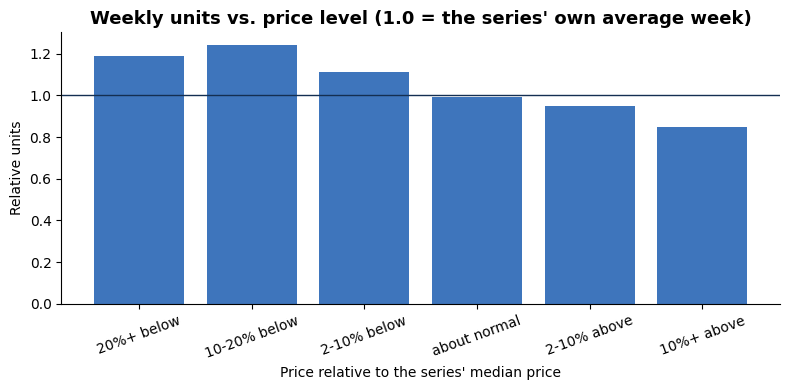

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(price_effect.index.astype(str), price_effect["avg_units_vs_own_average"], color=ACCENT)
ax.axhline(1, color=NAVY, linewidth=1)
ax.set_title("Weekly units vs. price level (1.0 = the series' own average week)")
ax.set_xlabel("Price relative to the series' median price"); ax.set_ylabel("Relative units")
plt.xticks(rotation=20)
save_chart("prices_units_vs_price_level")

## 7. Demand patterns: intermittency and demand types

Series are classified by two numbers computed from the days *after* an item's first sale:
**ADI** (average days between sales; high = sporadic) and **CV²** (squared variation of non-zero sale sizes; high = erratic sizes).
Standard cut-offs: ADI 1.32 and CV² 0.49 give four types: *smooth, erratic, intermittent, lumpy*.

In [35]:
def adi_cv2(vals, first_sale, chunk=5000):
    n, T = vals.shape
    adi = np.full(n, np.nan); cv2 = np.full(n, np.nan)
    for s in range(0, n, chunk):
        v = vals[s:s + chunk].astype(np.float64)
        nz = v > 0
        k = nz.sum(axis=1)
        okk = k > 0
        kk = np.maximum(k, 1)
        mean = (v * nz).sum(axis=1) / kk
        var = np.maximum(((v ** 2) * nz).sum(axis=1) / kk - mean ** 2, 0)
        cv2[s:s + chunk] = np.where(okk, var / np.where(mean > 0, mean, 1) ** 2, np.nan)
        adi[s:s + chunk] = np.where(okk, (T - first_sale[s:s + chunk]) / kk, np.nan)
    return adi, cv2

adi, cv2 = adi_cv2(vals, first_sale)
ADI_CUT, CV2_CUT = 1.32, 0.49
dtype_ = np.where(np.isnan(adi), "No sales",
          np.where(adi < ADI_CUT, np.where(cv2 < CV2_CUT, "Smooth", "Erratic"),
                                  np.where(cv2 < CV2_CUT, "Intermittent", "Lumpy")))
series["demand_type"] = dtype_

overall = series["demand_type"].value_counts()
print((overall / overall.sum() * 100).round(1).rename("% of series").to_frame())
print()
display((pd.crosstab(series["cat_id"], series["demand_type"], normalize="index") * 100).round(1))

              % of series
demand_type              
Intermittent         72.7
Lumpy                18.3
Smooth                6.2
Erratic               2.8



demand_type,Erratic,Intermittent,Lumpy,Smooth
cat_id,,,,
FOODS,4.5,60.6,26.6,8.3
HOBBIES,0.9,79.7,18.5,0.8
HOUSEHOLD,1.6,85.4,6.7,6.3


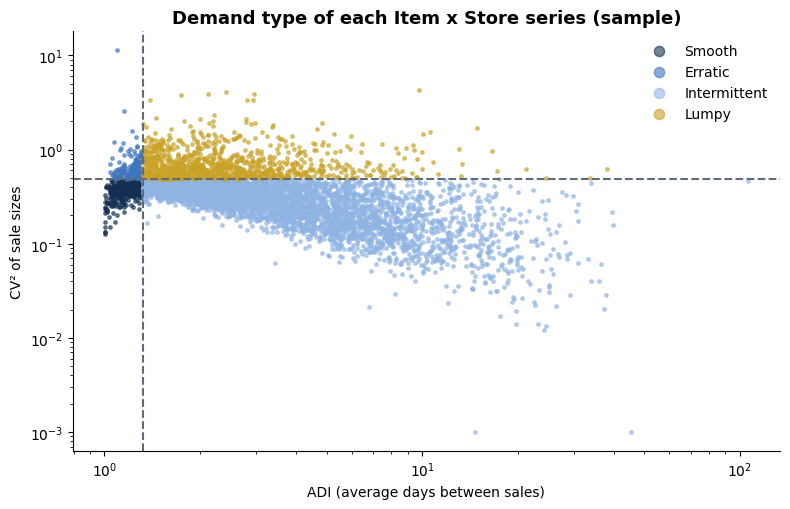

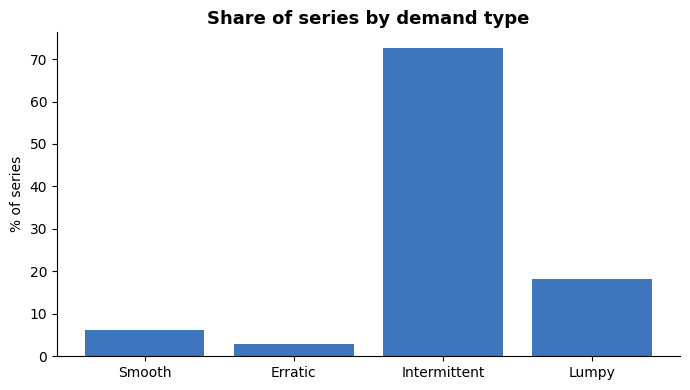

In [36]:
rng = np.random.default_rng(0)
ok = ~np.isnan(adi)
idx = rng.choice(np.flatnonzero(ok), size=min(6000, int(ok.sum())), replace=False)
colors = {"Smooth": NAVY, "Erratic": ACCENT, "Intermittent": LIGHT, "Lumpy": "#C9A227"}

fig, ax = plt.subplots(figsize=(8, 5.2))
for name, col in colors.items():
    m = dtype_[idx] == name
    ax.scatter(adi[idx][m], np.clip(cv2[idx][m], 1e-3, None), s=6, color=col, label=name, alpha=0.6)
ax.axvline(ADI_CUT, color=GRAY, linestyle="--"); ax.axhline(CV2_CUT, color=GRAY, linestyle="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ADI (average days between sales)"); ax.set_ylabel("CV² of sale sizes")
ax.set_title("Demand type of each Item x Store series (sample)")
ax.legend(frameon=False, markerscale=3)
save_chart("demand_types_scatter")

fig, ax = plt.subplots(figsize=(7, 4))
share = (overall / overall.sum() * 100).reindex(["Smooth", "Erratic", "Intermittent", "Lumpy", "No sales"]).dropna()
ax.bar(share.index, share.values, color=ACCENT)
ax.set_title("Share of series by demand type"); ax.set_ylabel("% of series")
save_chart("demand_types_share")

## 8. Scope sizing: how much of the value does a manageable subset keep?

In [37]:
rank = series["revenue"].rank(ascending=False, method="first").to_numpy()
def scope_row(name, mask):
    mask = np.asarray(mask)
    return {"scope": name, "series": int(mask.sum()),
            "% of series": round(mask.mean() * 100, 1),
            "% of units": round(series.loc[mask, "units"].sum() / series["units"].sum() * 100, 1),
            "% of est. revenue": round(series.loc[mask, "revenue"].sum() / series["revenue"].sum() * 100, 1),
            "daily observations (millions)": round(mask.sum() * n_days / 1e6, 2)}

opts = [scope_row("Everything", np.ones(n_series, bool))]
for st in sorted(series["state_id"].unique()):
    opts.append(scope_row(f"State {st}", (series["state_id"] == st).to_numpy()))
for ct in sorted(series["cat_id"].unique()):
    opts.append(scope_row(f"Category {ct}", (series["cat_id"] == ct).to_numpy()))
for n in (500, 1000, 3000, 5000):
    opts.append(scope_row(f"Top {n:,} series by revenue", rank <= n))
scope_table = pd.DataFrame(opts)
scope_table

,scope,series,% of series,% of units,% of est. revenue,daily observations (millions)
0,Everything,30490,100.0,100.0,100.0,59.18
1,State CA,12196,40.0,43.6,44.9,23.67
2,State TX,9147,30.0,28.7,28.8,17.75
3,State WI,9147,30.0,27.6,26.4,17.75
4,Category FOODS,14370,47.1,68.6,58.0,27.89
5,Category HOBBIES,5650,18.5,9.3,12.2,10.97
6,Category HOUSEHOLD,10470,34.3,22.1,29.8,20.32
7,Top 500 series by revenue,500,1.6,17.3,18.3,0.97
8,"Top 1,000 series by revenue",1000,3.3,24.4,26.8,1.94
9,"Top 3,000 series by revenue",3000,9.8,42.9,46.7,5.82


## 9. Findings and implications

In [38]:
facts = pd.DataFrame([
    ["Series x days (observations)",                  f"{n_series:,} x {n_days:,} ({vals.size / 1e6:,.1f} M)"],
    ["Zero-sales share (all / after first sale)",     f"{zero_mask.mean():.1%} / {(zero_mask & after_first).sum() / max(after_first.sum(), 1):.1%}"],
    ["Price coverage in sales window",                f"{(~no_price).mean():.1%}"],
    ["Series needed for 80% of revenue",              f"{int(np.searchsorted(cum, 0.8)) + 1:,} ({(np.searchsorted(cum, 0.8) + 1) / n_series:.0%} of series)"],
    ["Strongest / weakest weekday",                   f"{dow_idx.idxmax()} ({dow_idx.max():.2f}) / {dow_idx.idxmin()} ({dow_idx.min():.2f})"],
    ["Strongest / weakest month",                     f"{month_idx.idxmax()} ({month_idx.max():.2f}) / {month_idx.idxmin()} ({month_idx.min():.2f})"],
    ["Largest event increase / decrease",             f"{ev_sum.index[-1]} ({ev_sum['avg_lift_%'].iloc[-1]:+.0f}%) / {ev_sum.index[0]} ({ev_sum['avg_lift_%'].iloc[0]:+.0f}%)"],
    ["Share of series that are intermittent or lumpy", f"{series['demand_type'].isin(['Intermittent', 'Lumpy']).mean():.1%}"],
    ["Series with at least one price change",         f"{varying.mean():.1%}"],
], columns=["fact", "value"])
facts

,fact,value
0,Series x days (observations),"30,490 x 1,941 (59.2 M)"
1,Zero-sales share (all / after first sale),68.0% / 59.5%
2,Price coverage in sales window,79.3%
3,Series needed for 80% of revenue,"11,222 (37% of series)"
4,Strongest / weakest weekday,Sat (1.21) / Wed (0.87)
5,Strongest / weakest month,8 (1.07) / 1 (0.91)
6,Largest event increase / decrease,LaborDay (+24%) / Christmas (-100%)
7,Share of series that are intermittent or lumpy,90.9%
8,Series with at least one price change,72.8%


### Implications for modeling (complete after the findings above are filled in)

| Finding | Evidence (from this notebook) | Implication for the project |
|---|---|---|
| Leading zeros / missing price weeks | Section 2.2 | Trim each series from its first sale; do not treat pre-launch zeros as demand. |
| Strong weekday and yearly seasonality | Section 4 | Include calendar features; test seasonal models. |
| Event and SNAP effects | Section 5 | Use event and SNAP flags as model inputs. |
| Price and sales move together | Section 6 | Use price as a feature; check it in the evaluation period. |
| Many intermittent / lumpy series | Section 7 | Use methods suited to many zeros; consider quantile or uncertainty forecasts. |
| Revenue concentrated in few series | Sections 3 and 8 | A top-N or single-state scope can keep most of the value. |
| Observed sales are not true demand (stock-outs are not recorded) | Data has no inventory field | State this limit when interpreting recommendations. |

*Rows should be edited to match what the data actually showed.*

## Appendix: Data dictionary (from the M5 documentation)

In [39]:
dictionary = pd.DataFrame([
    ["calendar", "date",         "date",   "Calendar date"],
    ["calendar", "wm_yr_wk",     "int",    "Walmart week identifier (links to sell_prices)"],
    ["calendar", "weekday / wday","text/int","Day name / day number (1 = Saturday)"],
    ["calendar", "month / year", "int",    "Month and year"],
    ["calendar", "d",            "text",   "Day identifier d_1, d_2, ... (links to sales columns)"],
    ["calendar", "event_name_1/2, event_type_1/2", "text", "Event name and type (Sporting, Cultural, National, Religious); empty = no event"],
    ["calendar", "snap_CA / TX / WI", "0/1", "1 if SNAP purchases are allowed that day in the state"],
    ["sell_prices", "store_id",  "text",   "Store identifier (e.g. CA_1)"],
    ["sell_prices", "item_id",   "text",   "Item identifier (e.g. HOBBIES_1_001)"],
    ["sell_prices", "wm_yr_wk",  "int",    "Walmart week identifier"],
    ["sell_prices", "sell_price","float",  "Selling price of the item in that store that week; no row = not sold"],
    ["sales", "id",              "text",   "Item x Store identifier"],
    ["sales", "item_id / dept_id / cat_id", "text", "Item, department, and category"],
    ["sales", "store_id / state_id", "text", "Store and state"],
    ["sales", "d_1 ... d_1941",  "int",    "Units sold per day, one column per day"],
], columns=["file", "variable", "type", "description"])
dictionary

,file,variable,type,description
0,calendar,date,date,Calendar date
1,calendar,wm_yr_wk,int,Walmart week identifier (links to sell_prices)
2,calendar,weekday / wday,text/int,Day name / day number (1 = Saturday)
3,calendar,month / year,int,Month and year
4,calendar,d,text,"Day identifier d_1, d_2, ... (links to sales c..."
5,calendar,"event_name_1/2, event_type_1/2",text,"Event name and type (Sporting, Cultural, Natio..."
6,calendar,snap_CA / TX / WI,0/1,1 if SNAP purchases are allowed that day in th...
7,sell_prices,store_id,text,Store identifier (e.g. CA_1)
8,sell_prices,item_id,text,Item identifier (e.g. HOBBIES_1_001)
9,sell_prices,wm_yr_wk,int,Walmart week identifier


# Adding Weather as an Effect

Data comes directly from the noaa website (URL) and we don't need the csvs in our drive to run this

In [40]:

# Source: NOAA NCEI Access Data Service, dataset "daily-summaries" (GHCN-Daily). No token needed.
# Units: temperature in deg F, precipitation and snowfall in inches, wind in mph.

import io, os, time
import pandas as pd
import requests

M5_START, M5_END = "2011-01-29", "2016-06-19"      # d_1 to d_1969 (sales end at d_1941 = 2016-05-22)

# M5 does not say where its stores are, so each state is represented by its big-city airports.
STATIONS = {
    "CA": {"USW00023174": "Los Angeles Intl", "USW00023234": "San Francisco Intl",
           "USW00023188": "San Diego Intl",   "USW00023232": "Sacramento"},
    "TX": {"USW00012960": "Houston Intercontinental", "USW00003927": "Dallas-Fort Worth",
           "USW00012921": "San Antonio Intl",         "USW00013904": "Austin-Bergstrom"},
    "WI": {"USW00014839": "Milwaukee Mitchell", "USW00014837": "Madison Dane County",
           "USW00014898": "Green Bay"},
}
VARS = ["TMAX", "TMIN", "PRCP", "SNOW", "AWND"]
URL = "https://www.ncei.noaa.gov/access/services/data/v1"


def fetch_station(station_id, tries=4):
    params = {"dataset": "daily-summaries", "stations": station_id,
              "startDate": M5_START, "endDate": M5_END, "dataTypes": ",".join(VARS),
              "units": "standard", "format": "csv", "includeStationName": "true"}
    for attempt in range(tries):
        try:
            r = requests.get(URL, params=params, timeout=120)
            r.raise_for_status()
            return pd.read_csv(io.StringIO(r.text))
        except Exception as e:                      # NOAA occasionally times out; wait and retry
            if attempt == tries - 1:
                raise
            print(f"  retrying {station_id} ({e})")
            time.sleep(5 * (attempt + 1))


def build_weather(raw):
    """raw: one row per station per day. Returns one row per state per day."""
    raw = raw.copy()
    raw["date"] = pd.to_datetime(raw["DATE"])
    for v in VARS:                                  # a station may not report every variable
        raw[v] = pd.to_numeric(raw[v], errors="coerce") if v in raw.columns else float("nan")
    g = raw.groupby(["state_id", "date"])
    wx = g[VARS].mean().rename(columns={"TMAX": "tmax_f", "TMIN": "tmin_f", "PRCP": "prcp_in",
                                        "SNOW": "snow_in", "AWND": "wind_mph"})
    wx["n_stations"] = g["TMAX"].count()            # stations reporting a high that day
    wx = wx.reset_index()
    wx.insert(4, "tavg_f", (wx["tmax_f"] + wx["tmin_f"]) / 2)
    wx["rain_day"] = (wx["prcp_in"] >= 0.1).astype("int8")
    wx["snow_day"] = (wx["snow_in"].fillna(0) >= 1.0).astype("int8")
    # M5 day id: d_1 is 2011-01-29
    day_no = (wx["date"] - pd.Timestamp(M5_START)).dt.days + 1
    wx.insert(0, "d", "d_" + day_no.astype(str))
    num = wx.select_dtypes('number').columns
    wx[num] = wx[num].round(2)
    return wx


frames = []
for state, stations in STATIONS.items():
    for sid, label in stations.items():
        print(f"Downloading {state} - {label} ({sid})")
        df = fetch_station(sid)
        df["state_id"] = state
        frames.append(df)
weather_raw = pd.concat(frames, ignore_index=True)
weather = build_weather(weather_raw)

# --- Checks ---
expected_days = len(pd.date_range(M5_START, M5_END))
print(f"\nExpected days per state: {expected_days}")
print(weather.groupby("state_id").agg(days=("date", "count"), first=("d", "first"), last=("d", "last"),
                                      avg_high=("tmax_f", "mean"), total_rain=("prcp_in", "sum"),
                                      missing_tmax=("tmax_f", lambda s: int(s.isna().sum()))).round(1))

# --- Save next to the M5 files if the notebook's BASE_PATH exists, otherwise in the working folder ---
out_dir = globals().get("BASE_PATH") or "./"
if not os.access(out_dir, os.W_OK):
    out_dir = "./"
weather.to_csv(os.path.join(out_dir, "weather_by_state_day.csv"), index=False)
weather_raw.to_csv(os.path.join(out_dir, "weather_stations_raw.csv"), index=False)
print("Saved weather_by_state_day.csv and weather_stations_raw.csv to", out_dir)

# --- Side by side with M5: one row per state per day with units sold and weather ---
if all(k in globals() for k in ("vals", "series", "dates", "day_cols")):
    units = pd.concat([
        pd.DataFrame({"d": day_cols, "date": dates, "state_id": st,
                      "units": vals[(series["state_id"] == st).to_numpy()].sum(axis=0)})
        for st in sorted(series["state_id"].unique())], ignore_index=True)
    sales_weather = units.merge(weather.drop(columns="date"), on=["d", "state_id"], how="left")
    sales_weather.to_csv(os.path.join(out_dir, "sales_weather_by_state_day.csv"), index=False)
    print("Saved sales_weather_by_state_day.csv (state daily units + weather)")
    display(sales_weather.head())
else:
    print("M5 objects not found in this session, so only the weather files were written.")
    print("To join later: calendar.merge(weather, on='d') for each state, or merge on ['d', 'state_id'].")


# === Link weather to the sales grid, the same way the notebook links prices ===
# Nothing is merged. Weather is kept as a small state x day grid in the same day order as `vals`,
# and `series_state` says which state each row of `vals` belongs to.
#   weather_for("tmax_f")        -> series x days, lines up cell for cell with `vals`
#   weather_for("tmax_f", rows)  -> the same for a subset of rows
import numpy as np

WX_COLS = ["tmax_f", "tmin_f", "tavg_f", "prcp_in", "snow_in", "wind_mph", "rain_day", "snow_day"]

if all(k in globals() for k in ("vals", "series", "dates", "day_cols")):
    wx_states = sorted(weather["state_id"].unique())
    series_state = pd.Categorical(series["state_id"].astype(str), categories=wx_states).codes   # row of vals -> state
    assert (series_state >= 0).all(), "a series has a state with no weather"
    wx_state_day = {c: weather.pivot(index="state_id", columns="d", values=c)
                              .reindex(index=wx_states, columns=day_cols).to_numpy(dtype=np.float32)
                    for c in WX_COLS}

    def weather_for(col, rows=slice(None)):
        return wx_state_day[col][series_state[rows]]

    # --- Check that every series gets its own state's weather ---
    # 1) The state in each row's id (e.g. FOODS_1_001_CA_1_evaluation) must match the state whose weather it is given.
    state_in_id = series["store_id"].astype(str).str.split("_").str[0].to_numpy()
    state_given = np.array(wx_states)[series_state]
    assert (state_in_id == state_given).all(), "state mismatch between series and weather"
    # 2) Spot check: random series and days, looked up independently in the weather table by state and date.
    lookup_tbl = weather.set_index(["state_id", "date"])["tmax_f"]
    rng_chk = np.random.default_rng(0)
    for r, c in zip(rng_chk.integers(0, len(series), 500), rng_chk.integers(0, len(day_cols), 500)):
        expected = lookup_tbl.loc[(state_in_id[r], dates[c])]
        got = weather_for("tmax_f", [r])[0, c]
        assert (np.isnan(expected) and np.isnan(got)) or abs(expected - got) < 0.01, (r, c, expected, got)
    # 3) A table you can read: Wisconsin should be clearly the coldest and snowiest.
    print("\nWeather linked to sales rows. All state checks passed.")
    print(pd.DataFrame({"series": pd.Series(state_given).value_counts().reindex(wx_states).to_numpy(),
                        "avg_high_f": [np.nanmean(wx_state_day["tmax_f"][i]) for i in range(len(wx_states))],
                        "snow_days": [int(np.nansum(wx_state_day["snow_day"][i])) for i in range(len(wx_states))],
                        "days_missing_temp": [int(np.isnan(wx_state_day["tmax_f"][i]).sum()) for i in range(len(wx_states))]},
                       index=wx_states).round(1))


# === Optional: one long table, every Item x Store x Day row with the weather for its state that day ===
# Needs the EDA notebook's objects (vals, series, dates, day_cols) in the same session.
# The full table is 30,490 series x 1,941 days = about 59 million rows, so it is built with compact
# types and saved as Parquet (a CSV this size would be several GB). Pass a mask to build a subset.


def items_with_weather(mask=None):
    """mask: optional boolean array over `series` (e.g. series['state_id'] == 'WI'). Default: all series."""
    idx = np.arange(len(series)) if mask is None else np.flatnonzero(np.asarray(mask))
    n, T = len(idx), len(day_cols)
    sub = series.iloc[idx]
    out = {}
    for c in ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]:      # one value per series, repeated per day
        cat = pd.Categorical(sub[c].astype(str))
        out[c] = pd.Categorical.from_codes(np.repeat(cat.codes, T), cat.categories)
    out["d"] = pd.Categorical.from_codes(np.tile(np.arange(T, dtype=np.int16), n), day_cols)
    out["date"] = np.tile(dates.values, n)
    out["units"] = vals[idx].ravel().astype(np.int16)

    # Weather: a (state x day) grid per column, then picked out by each series' state
    states = sorted(weather["state_id"].unique())
    state_code = pd.Categorical(sub["state_id"].astype(str), categories=states).codes
    assert (state_code >= 0).all(), "a series has a state with no weather"
    for c in WX_COLS:
        grid = weather.pivot(index="state_id", columns="d", values=c).reindex(index=states, columns=day_cols)
        dtype = np.int8 if c.endswith("_day") else np.float32
        out[c] = grid.to_numpy()[state_code].ravel().astype(dtype)
    return pd.DataFrame(out)


# Not run automatically (about 59 million rows). To build and save it:
# items_weather = items_with_weather()                     # or items_with_weather(series["state_id"] == "WI")
# items_weather.to_parquet(os.path.join(out_dir, "items_weather_by_day.parquet"), index=False)


Expected days per state: 1969
          days first    last  avg_high  total_rain  missing_tmax
state_id                                                        
CA        1969   d_1  d_1969      71.1        62.6             0
TX        1969   d_1  d_1969      80.3       207.8             0
WI        1969   d_1  d_1969      56.1       182.7             0
Saved weather_by_state_day.csv and weather_stations_raw.csv to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/datasets/
Saved sales_weather_by_state_day.csv (state daily units + weather)


,d,date,state_id,units,tmax_f,tmin_f,tavg_f,prcp_in,snow_in,wind_mph,n_stations,rain_day,snow_day
0,d_1,2011-01-29,CA,14195,58.50,47.25,52.88,0.05,NaN,5.31,4,0,0
1,d_2,2011-01-30,CA,13805,57.75,49.25,53.50,0.24,NaN,7.94,4,1,0
2,d_3,2011-01-31,CA,10108,59.50,44.00,51.75,0.01,NaN,4.47,4,0,0
3,d_4,2011-02-01,CA,11047,62.25,44.50,53.38,0.00,NaN,6.99,4,0,0
4,d_5,2011-02-02,CA,9925,62.25,43.50,52.88,0.00,NaN,7.22,4,0,0



Weather linked to sales rows. All state checks passed.
    series  avg_high_f  snow_days  days_missing_temp
CA   12196   71.099998          0                  0
TX    9147   80.099998          0                  0
WI    9147   55.700001         85                  0


Sample look our our linked dataset

In [41]:
# Two random items per state, shown on one winter day and one summer day
pick = series.groupby("state_id").sample(2, random_state=1).index
preview = items_with_weather(series.index.isin(pick))

show_days = pd.to_datetime(["2013-01-15", "2013-07-15"])
display(preview[preview["date"].isin(show_days)].drop(columns=["dept_id", "cat_id"]))

print(f"Preview table: {len(preview):,} rows x {preview.shape[1]} columns "
      f"(the full dataset would be {len(series) * len(day_cols):,} rows)")

,id,item_id,store_id,state_id,d,date,units,tmax_f,tmin_f,tavg_f,prcp_in,snow_in,wind_mph,rain_day,snow_day
717,HOUSEHOLD_2_217_CA_1_evaluation,HOUSEHOLD_2_217,CA_1,CA,d_718,2013-01-15,0,55.000000,35.000000,45.00,0.00,NaN,3.41,0,0
898,HOUSEHOLD_2_217_CA_1_evaluation,HOUSEHOLD_2_217,CA_1,CA,d_899,2013-07-15,0,76.500000,59.500000,68.00,0.00,NaN,9.06,0,0
2658,HOUSEHOLD_2_461_CA_4_evaluation,HOUSEHOLD_2_461,CA_4,CA,d_718,2013-01-15,1,55.000000,35.000000,45.00,0.00,NaN,3.41,0,0
2839,HOUSEHOLD_2_461_CA_4_evaluation,HOUSEHOLD_2_461,CA_4,CA,d_899,2013-07-15,0,76.500000,59.500000,68.00,0.00,NaN,9.06,0,0
4599,HOUSEHOLD_1_498_TX_3_evaluation,HOUSEHOLD_1_498,TX_3,TX,d_718,2013-01-15,0,41.250000,34.250000,37.75,0.05,0.08,11.91,0,0
4780,HOUSEHOLD_1_498_TX_3_evaluation,HOUSEHOLD_1_498,TX_3,TX,d_899,2013-07-15,0,82.750000,70.750000,76.75,0.44,0.00,6.88,1,0
6540,FOODS_3_177_TX_3_evaluation,FOODS_3_177,TX_3,TX,d_718,2013-01-15,0,41.250000,34.250000,37.75,0.05,0.08,11.91,0,0
6721,FOODS_3_177_TX_3_evaluation,FOODS_3_177,TX_3,TX,d_899,2013-07-15,0,82.750000,70.750000,76.75,0.44,0.00,6.88,1,0
8481,FOODS_2_083_WI_2_evaluation,FOODS_2_083,WI_2,WI,d_718,2013-01-15,8,29.330000,11.670000,20.50,0.00,0.00,6.26,0,0
8662,FOODS_2_083_WI_2_evaluation,FOODS_2_083,WI_2,WI,d_899,2013-07-15,1,88.669998,67.330002,78.00,0.00,0.00,4.47,0,0


Preview table: 11,646 rows x 17 columns (the full dataset would be 59,181,090 rows)


Sample Charts of weekly item units bought in California and their corresponding weather

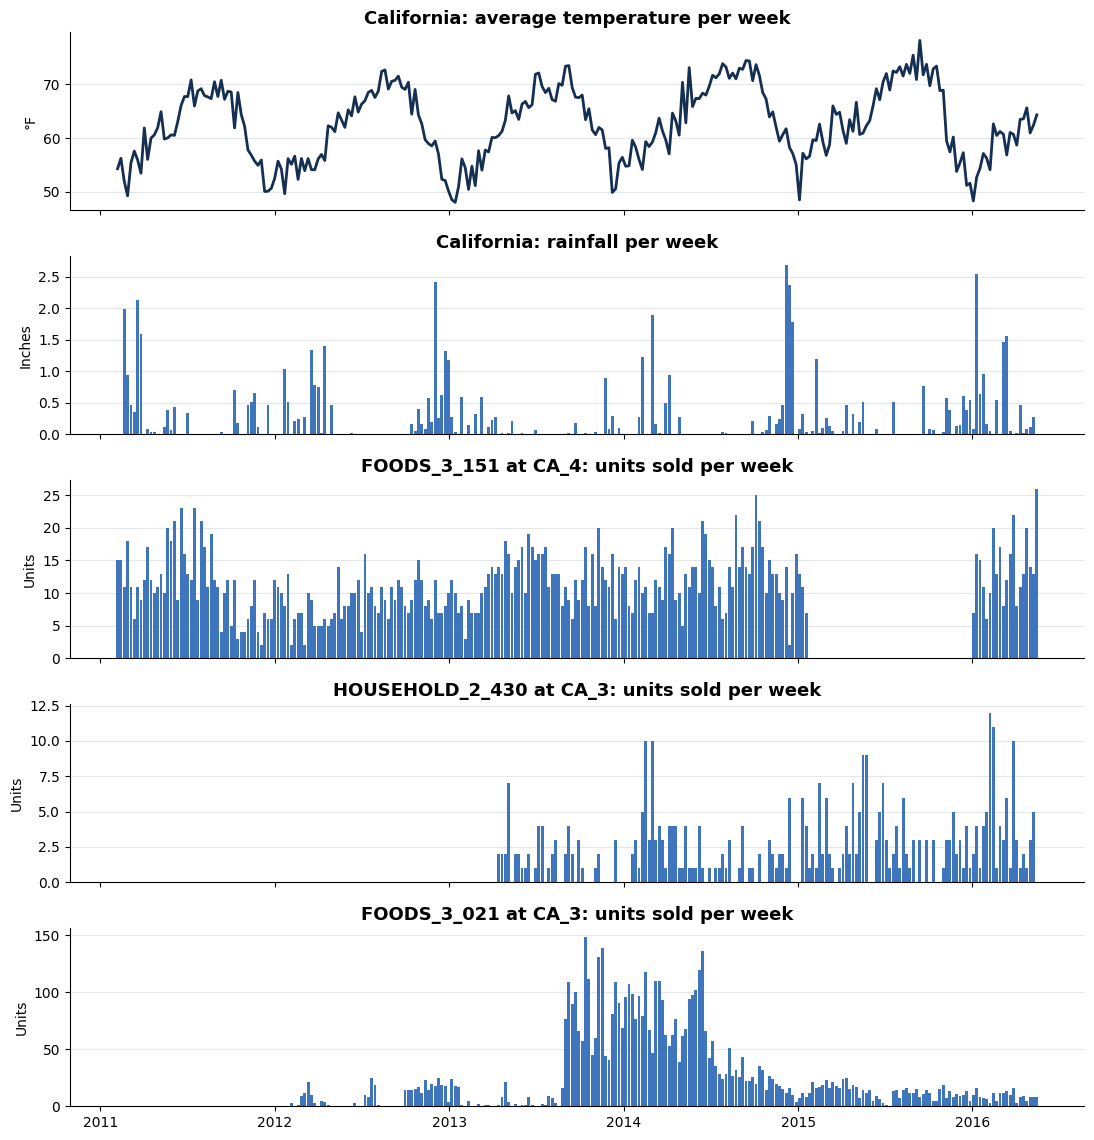

,corr. with temperature,corr. with rainfall
FOODS_3_151 / CA_4,0.04,-0.02
HOUSEHOLD_2_430 / CA_3,0.01,0.07
FOODS_3_021 / CA_3,0.05,-0.10


In [42]:
# California: weekly weather next to weekly units for a few random items
N_ITEMS, SEED = 3, 7            # change SEED for a different random set of items

ca_rows = np.flatnonzero((series["state_id"] == "CA").to_numpy())
pick = np.random.default_rng(SEED).choice(ca_rows, N_ITEMS, replace=False)

def weekly(x, how):             # daily -> weekly, dropping the partial first and last weeks
    return pd.Series(x, index=dates).resample("W").agg(how).iloc[1:-1]

temp = weekly(weather_for("tavg_f", [ca_rows[0]])[0], "mean")
rain = weekly(weather_for("prcp_in", [ca_rows[0]])[0], "sum")

fig, axes = plt.subplots(2 + N_ITEMS, 1, figsize=(11, 2.3 * (2 + N_ITEMS)), sharex=True)
axes[0].plot(temp.index, temp.values, color=NAVY, linewidth=2)
axes[0].set_title("California: average temperature per week"); axes[0].set_ylabel("°F")
axes[1].bar(rain.index, rain.values, width=6, color=ACCENT)
axes[1].set_title("California: rainfall per week"); axes[1].set_ylabel("Inches")
for ax, r in zip(axes[2:], pick):
    u = weekly(vals[r], "sum")
    ax.bar(u.index, u.values, width=6, color=ACCENT)
    ax.set_title(f"{series['item_id'].iloc[r]} at {series['store_id'].iloc[r]}: units sold per week")
    ax.set_ylabel("Units")
for ax in axes:
    ax.grid(axis="y", color="#E3E7EC", linewidth=0.8); ax.set_axisbelow(True)
save_chart("ca_weather_vs_items")

# How closely each item's weekly units track the weather (-1 to +1; near 0 = no relationship)
pd.DataFrame({f"{series['item_id'].iloc[r]} / {series['store_id'].iloc[r]}":
              {"corr. with temperature": weekly(vals[r], "sum").corr(temp),
               "corr. with rainfall": weekly(vals[r], "sum").corr(rain)} for r in pick}).T.round(2)

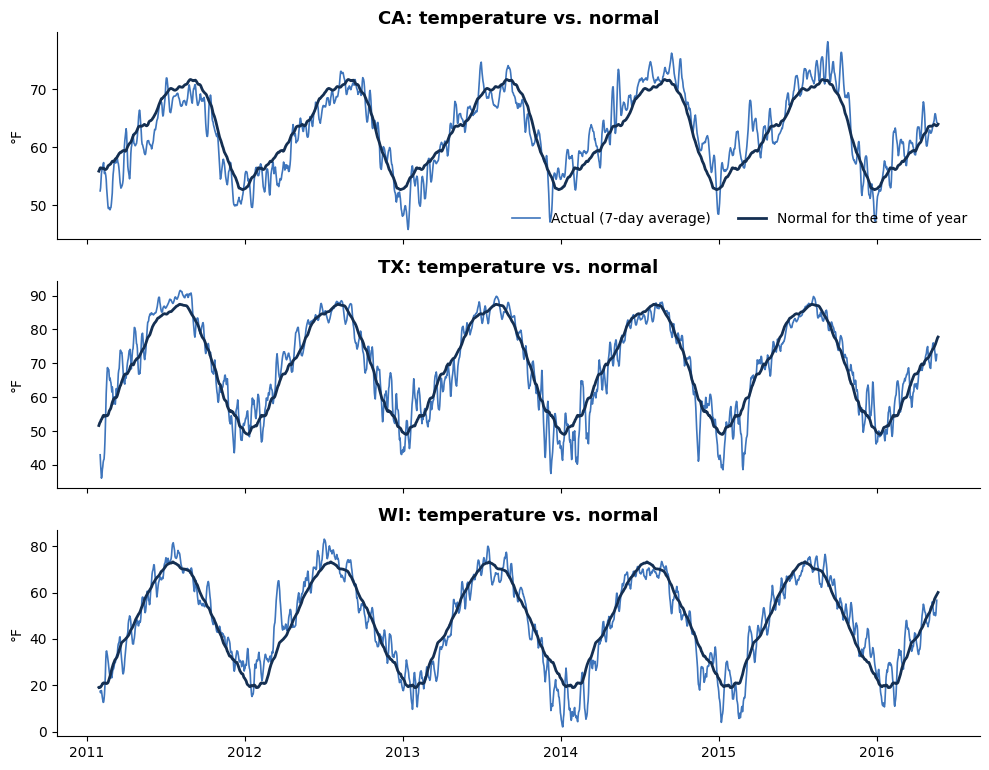

Unusually hot / cold = warmest / coldest 10% of days relative to normal. Cut-offs in °F vs. normal:


,hot at or above,cold at or below
state_id,,
CA,4.6,-4.5
TX,8.2,-8.5
WI,10.9,-10.7


In [43]:
# Question: once the weekday and seasonal patterns are removed, do unusual weather days sell differently?
# =====================================================================================
from matplotlib.colors import LinearSegmentedColormap

MIN_DAYS = 10                                   # cells with fewer weather days than this are not reported
wx = weather[weather["d"].isin(day_cols)].copy()            # sales window only
wx_states = sorted(wx["state_id"].unique())
cats = sorted(series["cat_id"].unique())

# ---- 1. Temperature anomaly: degrees above or below normal for that state and time of year ----
# "Normal" = that state's average for the day of year over the whole period, smoothed over 31 days.
wx["doy"] = wx["date"].dt.dayofyear.clip(upper=365)
wx["normal_f"] = np.nan
for st in wx_states:
    m = wx["state_id"] == st
    clim = wx.loc[m].groupby("doy")["tavg_f"].mean().reindex(range(1, 366)).interpolate(limit_direction="both")
    wrapped = pd.concat([clim.iloc[-15:], clim, clim.iloc[:15]])          # wrap around the year end
    smooth = wrapped.rolling(31, center=True).mean().iloc[15:-15]
    wx.loc[m, "normal_f"] = wx.loc[m, "doy"].map(smooth)
wx["anom_f"] = wx["tavg_f"] - wx["normal_f"]

fig, axes = plt.subplots(len(wx_states), 1, figsize=(10, 2.6 * len(wx_states)), sharex=True)
for ax, st in zip(axes, wx_states):
    g = wx[wx["state_id"] == st].set_index("date")
    ax.plot(g.index, g["tavg_f"].rolling(7, center=True).mean(), color=ACCENT, linewidth=1.2, label="Actual (7-day average)")
    ax.plot(g.index, g["normal_f"], color=NAVY, linewidth=2, label="Normal for the time of year")
    ax.set_title(f"{st}: temperature vs. normal"); ax.set_ylabel("°F")
axes[0].legend(frameon=False, ncol=2, loc="lower right")
save_chart("weather_temperature_vs_normal")

# ---- Weather-day definitions (per state, so every state has a comparable number of hot and cold days) ----
hot_cut  = wx.groupby("state_id")["anom_f"].quantile(0.90)
cold_cut = wx.groupby("state_id")["anom_f"].quantile(0.10)
wx["Rain day"] = wx["prcp_in"] >= 0.1
wx["Snow day"] = wx["snow_in"].fillna(0) >= 1.0
wx["Unusually hot"]  = wx["anom_f"] >= wx["state_id"].map(hot_cut)
wx["Unusually cold"] = wx["anom_f"] <= wx["state_id"].map(cold_cut)
CONDS = ["Rain day", "Snow day", "Unusually hot", "Unusually cold"]
print("Unusually hot / cold = warmest / coldest 10% of days relative to normal. Cut-offs in °F vs. normal:")
display(pd.DataFrame({"hot at or above": hot_cut, "cold at or below": cold_cut}).round(1))


Total units on weather days vs. local baseline (weekday-adjusted, event days excluded)


state,CA,TX,WI
days in sample,,,
Rain day,166,338,364
Snow day,0,0,76
Unusually hot,175,172,171
Unusually cold,174,183,174


state,CA,TX,WI
lift (± rough margin),,,
Rain day,-1.0% (±0.6),-1.1% (±0.6),-0.2% (±0.7)
Snow day,n/a,n/a,-7.5% (±1.8)
Unusually hot,+2.9% (±0.6),+2.2% (±0.7),+4.0% (±1.0)
Unusually cold,-0.5% (±0.6),-1.3% (±0.7),+2.4% (±1.0)


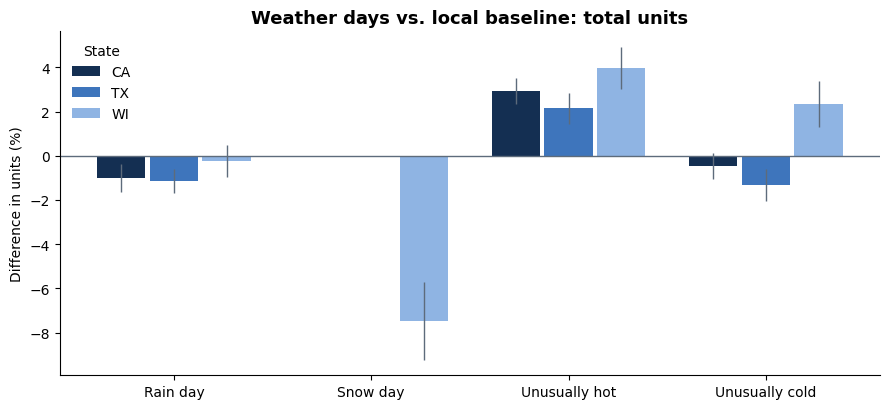

In [46]:

# ---- 2. Weather-day lift, same method as the event lift in Section 5 ----
# Remove the weekday pattern, compare each day with its 29-day local baseline, then average over weather days.
# Calendar event days are left out so holidays are not counted as weather.
event_day = cal_by_d.loc[day_cols, ["event_name_1", "event_name_2"]].notna().any(axis=1).to_numpy()

def lift_of(mask_rows):
    d = pd.Series(vals[mask_rows].sum(axis=0, dtype=np.int64), index=dates).astype(float)
    adj = d / (d.groupby(dates.dayofweek).mean() / d.mean()).reindex(dates.dayofweek).to_numpy()
    return (adj / adj.rolling(29, center=True, min_periods=15).median() - 1).to_numpy()

rows = []
for st in wx_states:
    g = wx[wx["state_id"] == st].set_index("d").reindex(day_cols)
    st_rows = (series["state_id"] == st).to_numpy()
    for scope in ["All"] + cats:
        m = st_rows if scope == "All" else st_rows & (series["cat_id"] == scope).to_numpy()
        lift = lift_of(m)
        for c in CONDS:
            x = lift[g[c].to_numpy(dtype=bool) & ~event_day]
            x = x[np.isfinite(x)]
            n = len(x)
            rows.append([st, scope, c, n, x.mean() * 100 if n >= MIN_DAYS else np.nan,
                         x.std(ddof=1) / np.sqrt(n) * 100 if n >= MIN_DAYS else np.nan])
wx_lift = pd.DataFrame(rows, columns=["state", "category", "weather", "days", "lift_%", "se_%"])
wx_lift["clear"] = wx_lift["lift_%"].abs() > 2 * wx_lift["se_%"]      # bigger than twice its rough margin of error

total = wx_lift[wx_lift["category"] == "All"]
print("Total units on weather days vs. local baseline (weekday-adjusted, event days excluded)")
display(total.pivot(index="weather", columns="state", values="days").reindex(CONDS).rename_axis("days in sample"))
display(total.assign(v=total["lift_%"].map("{:+.1f}%".format).where(total["lift_%"].notna(), "n/a")
                       + total["se_%"].map(" (±{:.1f})".format).where(total["lift_%"].notna(), ""))
             .pivot(index="weather", columns="state", values="v").reindex(CONDS).rename_axis("lift (± rough margin)"))

fig, ax = plt.subplots(figsize=(9, 4.2))
w = 0.8 / len(wx_states)
for i, (st, color) in enumerate(zip(wx_states, [NAVY, ACCENT, LIGHT])):
    t = total[total["state"] == st].set_index("weather").reindex(CONDS)
    ax.bar(np.arange(len(CONDS)) + (i - (len(wx_states) - 1) / 2) * w, t["lift_%"], w * 0.92, color=color, label=st,
           yerr=t["se_%"], error_kw={"ecolor": GRAY, "elinewidth": 1})
ax.axhline(0, color=GRAY, linewidth=1)
ax.set_xticks(range(len(CONDS))); ax.set_xticklabels(CONDS)
ax.set_title("Weather days vs. local baseline: total units"); ax.set_ylabel("Difference in units (%)")
ax.legend(frameon=False, title="State")
save_chart("weather_day_lift_by_state")


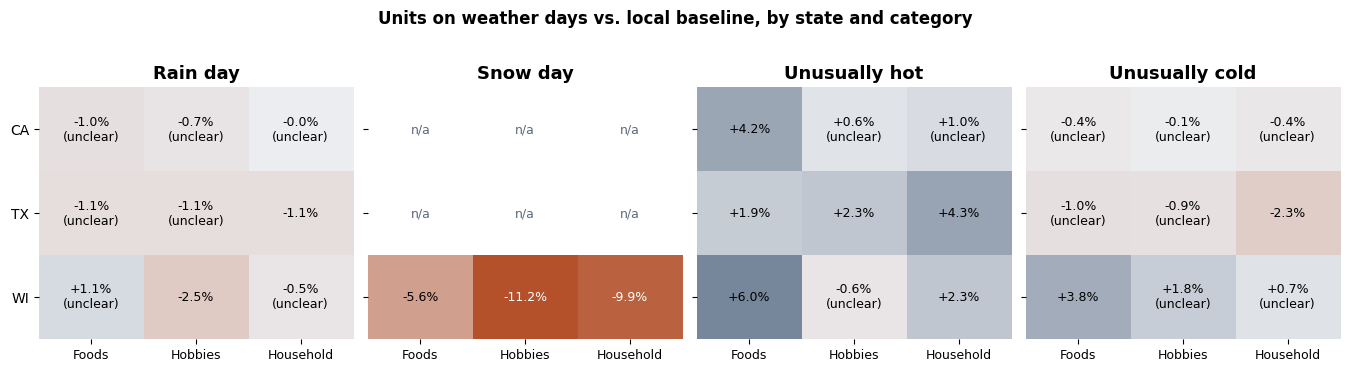

"(unclear)" = the difference is smaller than twice its rough margin of error, so treat it as no effect.
"n/a" = fewer than 10 such days in that state.
With this many comparisons, expect one or two to look clear by chance. Trust effects that are large, make sense, and repeat across categories.


In [47]:
# ---- 3. State x category heatmaps, like the SNAP heatmap ----
by_cat = wx_lift[wx_lift["category"] != "All"]
lim = max(1.0, np.nanmax(np.abs(by_cat["lift_%"])))
diverging = LinearSegmentedColormap.from_list("lift", ["#B4502A", "#ECEEF1", NAVY])     # fewer units / no change / more units
fig, axes = plt.subplots(1, len(CONDS), figsize=(3.4 * len(CONDS), 3.6), sharey=True)
for ax, c in zip(axes, CONDS):
    sub = by_cat[by_cat["weather"] == c]
    grid = sub.pivot(index="state", columns="category", values="lift_%").reindex(index=wx_states, columns=cats)
    clear = sub.pivot(index="state", columns="category", values="clear").reindex(index=wx_states, columns=cats)
    ax.imshow(np.ma.masked_invalid(grid.to_numpy()), cmap=diverging, vmin=-lim, vmax=lim, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            if np.isnan(v):
                ax.text(j, i, "n/a", ha="center", va="center", color=GRAY, fontsize=9); continue
            ax.text(j, i, f"{v:+.1f}%" + ("" if clear.iat[i, j] else "\n(unclear)"), ha="center", va="center",
                    fontsize=9, color="white" if abs(v) > 0.55 * lim else "black")
    ax.set_xticks(range(len(cats))); ax.set_xticklabels([k.title() for k in cats], fontsize=9)
    ax.set_yticks(range(len(wx_states))); ax.set_yticklabels(wx_states)
    ax.set_title(c); ax.spines[:].set_visible(False)
fig.suptitle("Units on weather days vs. local baseline, by state and category", fontweight="bold", y=1.02)
save_chart("weather_lift_state_category")
print('"(unclear)" = the difference is smaller than twice its rough margin of error, so treat it as no effect.')
print(f'"n/a" = fewer than {MIN_DAYS} such days in that state.')
print("With this many comparisons, expect one or two to look clear by chance. Trust effects that are large, "
      "make sense, and repeat across categories.")

From the heat maps above:


*   Snow days in Wisonsin are the streonges affect. All three categories clearly drop
*   Unusually hot days sell more. seven of the nine cells are positive, and food is up in every state
*   Rain is a weak baseline. most cells are unclear and the differnces of -1.1% and -2.5% are small
*   Unusually cold days show no pattern. Most are unclear, and the two effects that aren't unclear go in opposite direction, which looks like its more about chance than a real effect.








In [50]:
# Adds weather rows to the facts table and prints the row to paste into the implications table.
# =====================================================================================
ok = wx_lift[wx_lift["lift_%"].notna()]
tot_ok, cat_ok = ok[ok["category"] == "All"], ok[(ok["category"] != "All") & ok["clear"]]
describe = lambda r: f"{r['weather']} in {r['state']}" + ("" if r["category"] == "All" else f", {r['category']}") + f" ({r['lift_%']:+.1f}%)"
hi, lo = tot_ok.loc[tot_ok["lift_%"].idxmax()], tot_ok.loc[tot_ok["lift_%"].idxmin()]
strongest = describe(cat_ok.loc[cat_ok["lift_%"].abs().idxmax()]) if len(cat_ok) else "none clearly different from zero"
n_clear, n_tested = int(ok["clear"].sum()), len(ok)

pd.set_option("display.max_colwidth", None)
weather_facts = pd.DataFrame([
    ["Weather: largest increase / decrease in total units on a weather day", f"{describe(hi)} / {describe(lo)}"],
    ["Weather: strongest clear state x category effect",                     strongest],
    ["Weather: state x category x weather-type comparisons clearly different from zero", f"{n_clear} of {n_tested}"],
    ["Weather: source and limit", f"NOAA daily summaries, state average of up to {int(weather['n_stations'].max())} city stations per state; store locations are not in M5"],
], columns=["fact", "value"])
facts = pd.concat([facts[~facts["fact"].str.startswith("Weather:")], weather_facts], ignore_index=True)   # safe to re-run
display(facts)

print("-100% decrease on Christmas is from store closure")


,fact,value
0,Series x days (observations),"30,490 x 1,941 (59.2 M)"
1,Zero-sales share (all / after first sale),68.0% / 59.5%
2,Price coverage in sales window,79.3%
3,Series needed for 80% of revenue,"11,222 (37% of series)"
4,Strongest / weakest weekday,Sat (1.21) / Wed (0.87)
5,Strongest / weakest month,8 (1.07) / 1 (0.91)
6,Largest event increase / decrease,LaborDay (+24%) / Christmas (-100%)
7,Share of series that are intermittent or lumpy,90.9%
8,Series with at least one price change,72.8%
9,Weather: largest increase / decrease in total units on a weather day,Unusually hot in WI (+4.0%) / Snow day in WI (-7.5%)


-100% decrease on Christmas is from store closure
